# 04 — Exploratory Data Analysis (EDA)

## AgriShift: Agricultural Diversification & Crop Pattern Intelligence in India

This notebook explores the district-year features created in Notebook 03. The aim is to understand the shape, variation, and limitations of the data before selecting a clustering method.

### Questions explored
1. How are crop richness and diversification distributed across district-years?
2. Which district-year crop portfolios are most concentrated?
3. How do diversification indicators vary over time?
4. Which crops most often appear as dominant crops?
5. How is reported crop area distributed across seasons?

**Important interpretation:** crop shares are based on reported crop area summed across recorded seasons. This is gross reported crop area, not unique physical land area. A field may be cultivated in more than one season.

The analysis is descriptive. It does not establish why a district has a particular crop pattern or recommend what farmers should grow.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

## 1. Load the processed datasets

The notebook uses the outputs from Notebook 03. It does not modify the raw or cleaned source data.

In [2]:
FEATURES_FILE = Path("data/processed/district_year_diversification_features.csv")
CROP_MATRIX_FILE = Path("data/processed/district_year_crop_share_matrix.csv")
SEASON_MATRIX_FILE = Path("data/processed/district_year_season_share_matrix.csv")
PORTFOLIO_FILE = Path("data/processed/crop_portfolio_records.csv")

PROJECT_ROOT = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / FEATURES_FILE).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the processed datasets. Open this notebook from the AgriShift project."
    )

features = pd.read_csv(PROJECT_ROOT / FEATURES_FILE)
crop_matrix = pd.read_csv(PROJECT_ROOT / CROP_MATRIX_FILE)
season_matrix = pd.read_csv(PROJECT_ROOT / SEASON_MATRIX_FILE)
portfolio = pd.read_csv(PROJECT_ROOT / PORTFOLIO_FILE)

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Diversification features:", features.shape)
print("Crop-share matrix:", crop_matrix.shape)
print("Season-share matrix:", season_matrix.shape)
print("Portfolio records:", portfolio.shape)

Project folder: c:\Users\ajadi\OneDrive\Desktop\CSD\Exploration\AgriShift
Diversification features: (9839, 21)
Crop-share matrix: (9839, 119)
Season-share matrix: (9839, 9)
Portfolio records: (244802, 8)


## 2. Basic structure and data coverage

Check the observation period, district coverage, and completeness before interpreting the charts.

In [3]:
KEYS = ["State_Name", "District_Name", "Crop_Year"]

required_columns = KEYS + [
    "total_reported_crop_area_ha",
    "crop_richness",
    "shannon_entropy",
    "normalized_shannon_evenness",
    "hhi_concentration",
    "simpson_diversity",
    "effective_number_of_crops",
    "top_1_crop_share",
    "top_3_crop_share",
    "dominant_crop",
    "single_crop_observation",
]

missing_required = [column for column in required_columns if column not in features.columns]
if missing_required:
    raise KeyError(f"Missing expected feature columns: {missing_required}")

features["Crop_Year"] = pd.to_numeric(features["Crop_Year"], errors="raise").astype(int)

coverage = pd.DataFrame({
    "measure": [
        "District-year observations",
        "Unique state labels",
        "Unique district labels (name-based)",
        "First year",
        "Last year",
        "Unique crop categories in crop matrix",
        "Single-crop observations",
    ],
    "value": [
        len(features),
        features["State_Name"].nunique(),
        features[["State_Name", "District_Name"]].drop_duplicates().shape[0],
        features["Crop_Year"].min(),
        features["Crop_Year"].max(),
        crop_matrix.shape[1] - len(KEYS),
        int(features["single_crop_observation"].sum()),
    ],
})
display(coverage)
display(features.head())

,measure,value
0,District-year observations,9839
1,Unique state labels,33
2,Unique district labels (name-based),652
3,First year,1997
4,Last year,2015
5,Unique crop categories in crop matrix,116
6,Single-crop observations,27


,State_Name,District_Name,Crop_Year,total_reported_crop_area_ha,crop_richness,shannon_entropy,normalized_shannon_evenness,hhi_concentration,simpson_diversity,effective_number_of_crops,top_1_crop_share,top_3_crop_share,dominant_crop,crop_category_records,single_crop_observation,season_richness,season_shannon_entropy,normalized_season_evenness,season_hhi_concentration,dominant_season,in_common_name_panel_1997_2014
0,Andaman and Nicobar Islands,NICOBARS,2000,"20,504.0000",10,0.4896,0.2126,0.7902,0.2098,1.6317,0.8861,0.9823,Coconut,10,False,2,0.2438,0.3517,0.8763,Whole Year,False
1,Andaman and Nicobar Islands,NICOBARS,2001,"20,306.0000",8,0.4306,0.2071,0.8075,0.1925,1.5381,0.8958,0.9930,Coconut,8,False,2,0.2430,0.3506,0.8768,Whole Year,False
2,Andaman and Nicobar Islands,NICOBARS,2002,"21,147.5000",9,0.6087,0.2770,0.7492,0.2508,1.8381,0.8625,0.9560,Coconut,9,False,2,0.0511,0.0737,0.9823,Whole Year,False
3,Andaman and Nicobar Islands,NICOBARS,2003,"20,822.4400",9,0.5356,0.2438,0.7762,0.2238,1.7085,0.8781,0.9731,Coconut,9,False,2,0.0175,0.0252,0.9950,Whole Year,False
4,Andaman and Nicobar Islands,NICOBARS,2004,"20,726.2600",9,0.4921,0.2240,0.7926,0.2074,1.6357,0.8875,0.9815,Coconut,9,False,2,0.0178,0.0257,0.9949,Whole Year,False


## 3. Distribution of crop richness

Crop richness is the number of standardized crop categories recorded for a district in a given year. It is a count, not a direct measure of the quality or sustainability of a farming system.

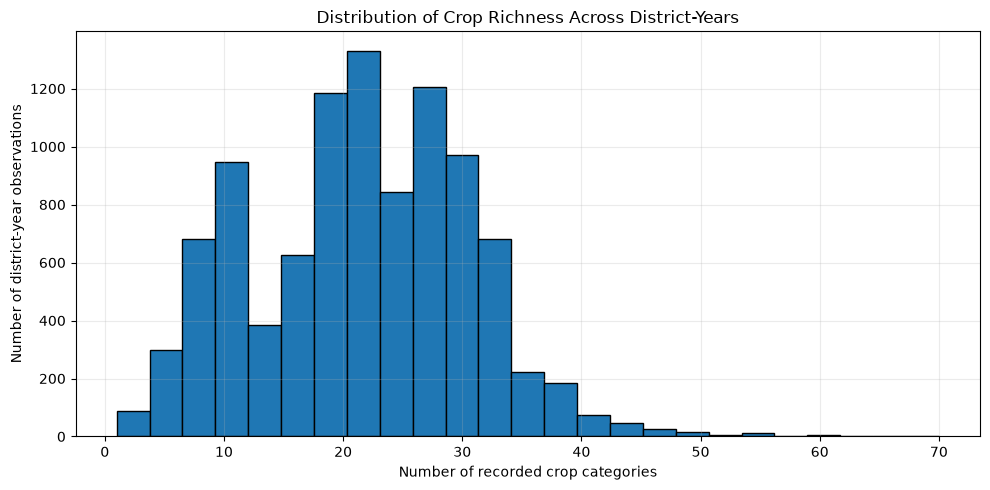

,crop_richness
count,"9,839.0000"
mean,21.6696
std,9.0268
min,1.0000
25%,15.0000
50%,22.0000
75%,28.0000
max,70.0000


In [4]:
fig, ax = plt.subplots()
ax.hist(features["crop_richness"].dropna(), bins=25, edgecolor="black")
ax.set_title("Distribution of Crop Richness Across District-Years")
ax.set_xlabel("Number of recorded crop categories")
ax.set_ylabel("Number of district-year observations")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_crop_richness_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

display(features["crop_richness"].describe().to_frame("crop_richness"))

## 4. Diversification and concentration indicators

Shannon entropy and normalized evenness describe how evenly reported crop area is distributed across crops. HHI concentration and top-crop share describe the extent to which area is concentrated in a small number of crops.

These indicators are related but not identical. Interpret them together rather than relying on one metric alone.

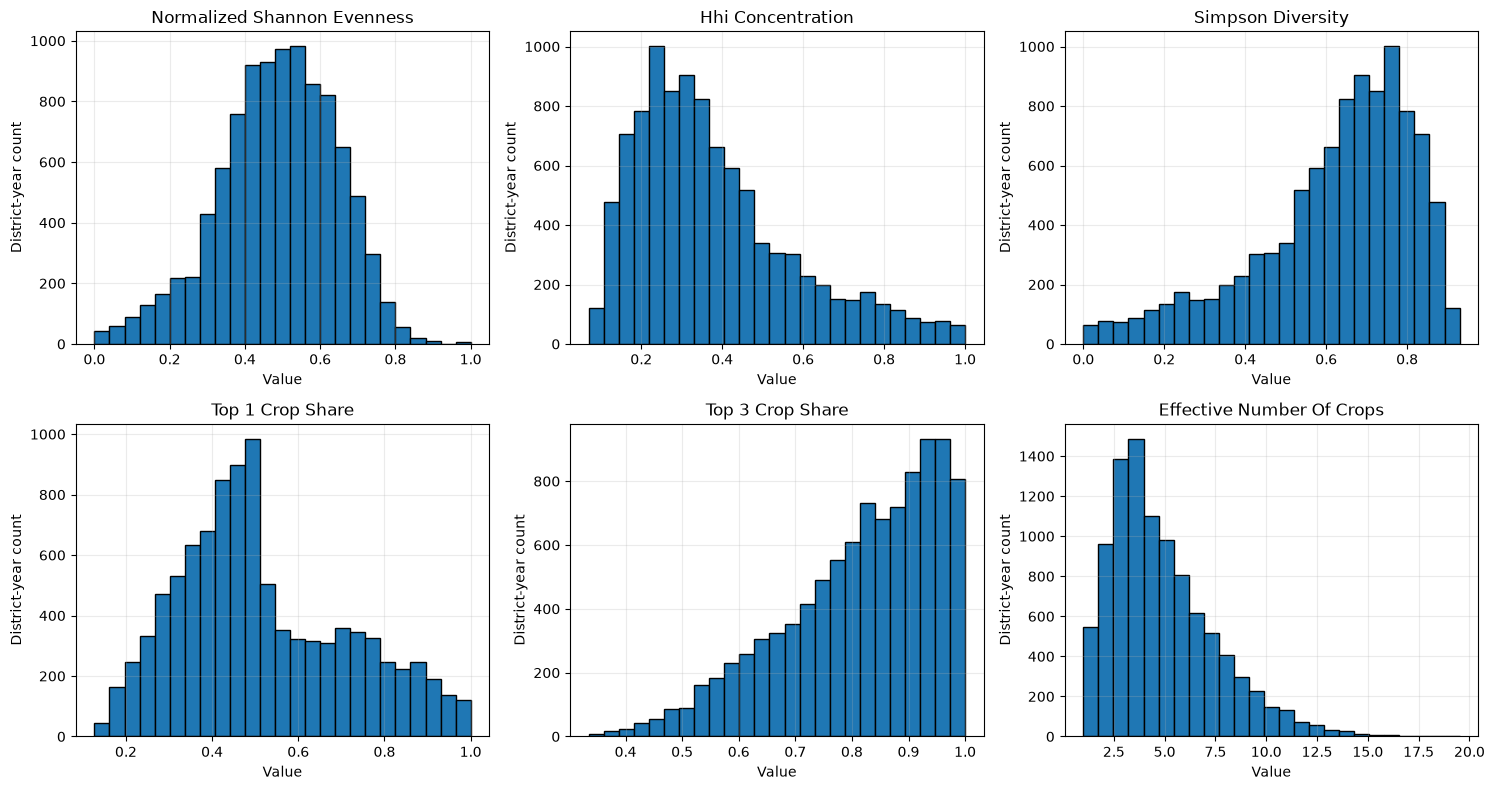

,count,mean,std,min,25%,50%,75%,max
normalized_shannon_evenness,"9,839.0000",0.4873,0.1565,0.0000,0.3895,0.4970,0.6017,0.9999
hhi_concentration,"9,839.0000",0.3788,0.1963,0.0705,0.2329,0.3341,0.4747,1.0000
simpson_diversity,"9,839.0000",0.6212,0.1963,0.0000,0.5253,0.6659,0.7671,0.9295
top_1_crop_share,"9,839.0000",0.5156,0.1966,0.1269,0.3731,0.4787,0.6560,1.0000
top_3_crop_share,"9,839.0000",0.8138,0.1366,0.3351,0.7286,0.8397,0.9268,1.0000
effective_number_of_crops,"9,839.0000",4.9025,2.5808,1.0000,3.0052,4.2765,6.3067,19.5138


In [5]:
metric_columns = [
    "normalized_shannon_evenness",
    "hhi_concentration",
    "simpson_diversity",
    "top_1_crop_share",
    "top_3_crop_share",
    "effective_number_of_crops",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, column in zip(axes.flat, metric_columns):
    ax.hist(features[column].dropna(), bins=25, edgecolor="black")
    ax.set_title(column.replace("_", " ").title())
    ax.set_xlabel("Value")
    ax.set_ylabel("District-year count")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_diversification_metric_distributions.png", dpi=160, bbox_inches="tight")
plt.show()

display(features[metric_columns].describe().T)

## 5. Relationship between diversification metrics

This correlation view is a descriptive check. Strong correlations may indicate that some features carry overlapping information. Correlation does not imply causation.

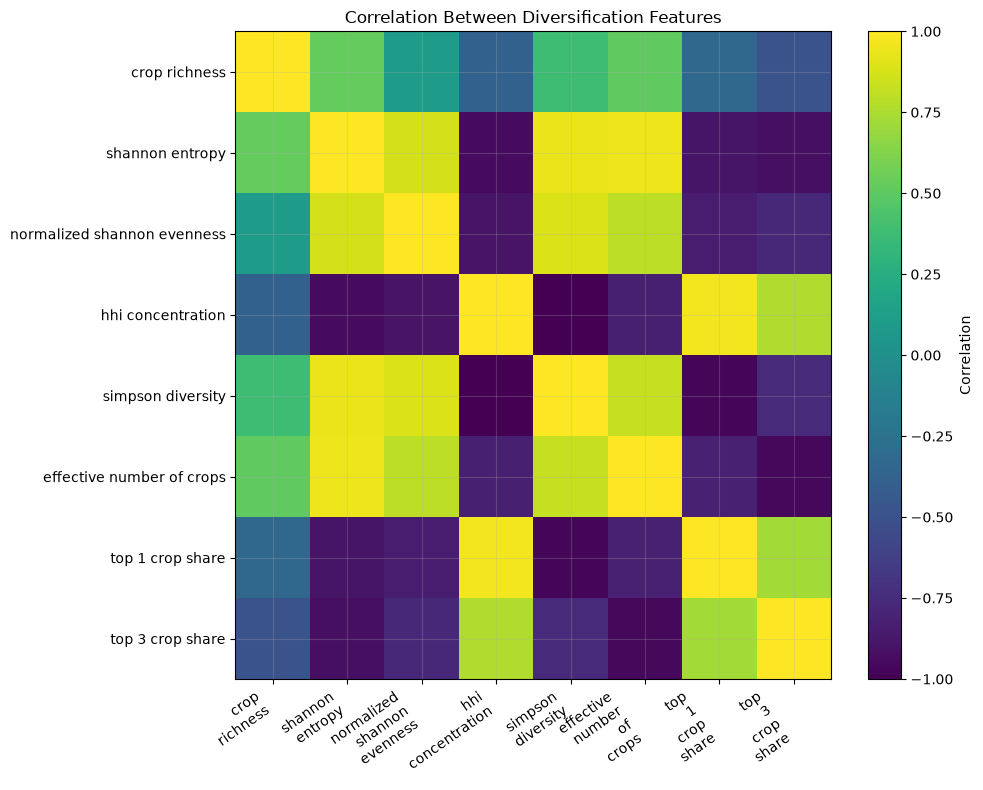

,crop_richness,shannon_entropy,normalized_shannon_evenness,hhi_concentration,simpson_diversity,effective_number_of_crops,top_1_crop_share,top_3_crop_share
crop_richness,1.0000,0.5250,0.1030,-0.3780,0.3780,0.5110,-0.3290,-0.4880
shannon_entropy,0.5250,1.0000,0.8680,-0.9390,0.9390,0.9490,-0.8860,-0.9180
normalized_shannon_evenness,0.1030,0.8680,1.0000,-0.8940,0.8940,0.7990,-0.8480,-0.7720
hhi_concentration,-0.3780,-0.9390,-0.8940,1.0000,-1.0000,-0.8280,0.9670,0.7610
simpson_diversity,0.3780,0.9390,0.8940,-1.0000,1.0000,0.8280,-0.9670,-0.7610
effective_number_of_crops,0.5110,0.9490,0.7990,-0.8280,0.8280,1.0000,-0.8130,-0.9590
top_1_crop_share,-0.3290,-0.8860,-0.8480,0.9670,-0.9670,-0.8130,1.0000,0.7210
top_3_crop_share,-0.4880,-0.9180,-0.7720,0.7610,-0.7610,-0.9590,0.7210,1.0000


In [6]:
correlation_columns = [
    "crop_richness",
    "shannon_entropy",
    "normalized_shannon_evenness",
    "hhi_concentration",
    "simpson_diversity",
    "effective_number_of_crops",
    "top_1_crop_share",
    "top_3_crop_share",
]

corr = features[correlation_columns].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(correlation_columns)))
ax.set_yticks(range(len(correlation_columns)))
ax.set_xticklabels([c.replace("_", "\n") for c in correlation_columns], rotation=35, ha="right")
ax.set_yticklabels([c.replace("_", " ") for c in correlation_columns])
ax.set_title("Correlation Between Diversification Features")
fig.colorbar(image, ax=ax, label="Correlation")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_feature_correlation.png", dpi=160, bbox_inches="tight")
plt.show()

display(corr.round(3))

## 6. Change in diversification indicators over time

The yearly averages are calculated across the district-year observations available in each year. Because coverage varies by year, these lines are not a perfectly balanced national panel. Treat changes as descriptive patterns, not proof of nationwide change.

,Crop_Year,district_year_observations,mean_crop_richness,median_crop_richness,mean_evenness,mean_hhi,mean_top1_share
0,1997,474,15.3397,14.0000,0.5161,0.4053,0.5389
1,1998,497,19.6821,21.0000,0.5085,0.3656,0.5014
2,1999,517,21.2128,22.0000,0.5080,0.3577,0.4998
3,2000,546,22.3315,23.0000,0.4980,0.3637,0.5053
4,2001,546,22.0293,22.0000,0.4948,0.3660,0.5059
5,2002,568,26.5299,24.0000,0.4835,0.3633,0.5054
6,2003,583,26.9160,26.0000,0.4908,0.3553,0.4982
7,2004,588,21.3350,23.0000,0.4849,0.3818,0.5203
8,2005,593,20.6526,21.0000,0.4778,0.3895,0.5260
9,2006,583,21.5523,23.0000,0.4848,0.3766,0.5128


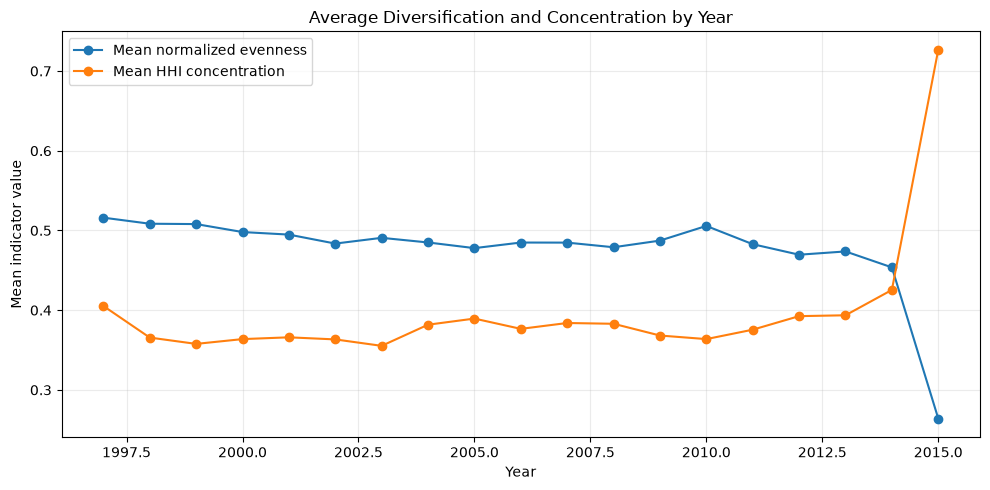

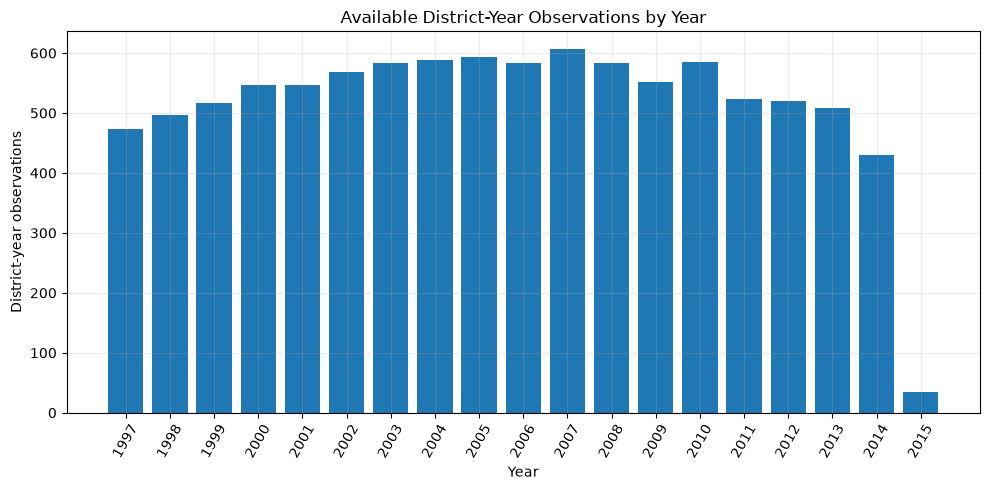

In [7]:
yearly = (
    features.groupby("Crop_Year")
    .agg(
        district_year_observations=("District_Name", "size"),
        mean_crop_richness=("crop_richness", "mean"),
        median_crop_richness=("crop_richness", "median"),
        mean_evenness=("normalized_shannon_evenness", "mean"),
        mean_hhi=("hhi_concentration", "mean"),
        mean_top1_share=("top_1_crop_share", "mean"),
    )
    .reset_index()
)

display(yearly)

fig, ax = plt.subplots()
ax.plot(yearly["Crop_Year"], yearly["mean_evenness"], marker="o", label="Mean normalized evenness")
ax.plot(yearly["Crop_Year"], yearly["mean_hhi"], marker="o", label="Mean HHI concentration")
ax.set_title("Average Diversification and Concentration by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Mean indicator value")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_yearly_diversification_trend.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots()
ax.bar(yearly["Crop_Year"].astype(str), yearly["district_year_observations"])
ax.set_title("Available District-Year Observations by Year")
ax.set_xlabel("Year")
ax.set_ylabel("District-year observations")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_yearly_observation_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Most frequent dominant crops

The dominant crop is the crop with the largest reported area share in a district-year. This table counts how often each crop is dominant in the dataset. It is not a ranking of crop productivity or profitability.

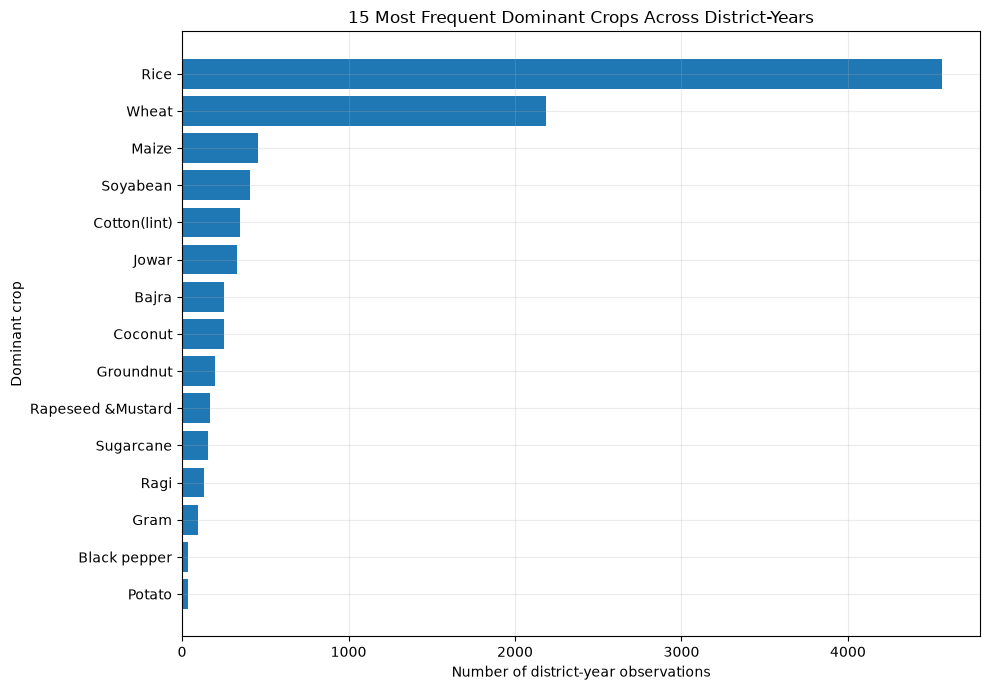

,dominant_crop,district_year_count
0,Rice,4565
1,Wheat,2186
2,Maize,454
3,Soyabean,408
4,Cotton(lint),347
5,Jowar,328
6,Bajra,250
7,Coconut,249
8,Groundnut,198
9,Rapeseed &Mustard,165


In [8]:
dominant_counts = (
    features["dominant_crop"]
    .value_counts()
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(dominant_counts.index, dominant_counts.values)
ax.set_title("15 Most Frequent Dominant Crops Across District-Years")
ax.set_xlabel("Number of district-year observations")
ax.set_ylabel("Dominant crop")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "eda_most_frequent_dominant_crops.png", dpi=160, bbox_inches="tight")
plt.show()

display(
    features["dominant_crop"]
    .value_counts()
    .head(15)
    .rename_axis("dominant_crop")
    .reset_index(name="district_year_count")
)

## 8. Season-level reported area distribution

This section uses the season-share matrix. Season columns are identified from the matrix after excluding the three district-year keys.

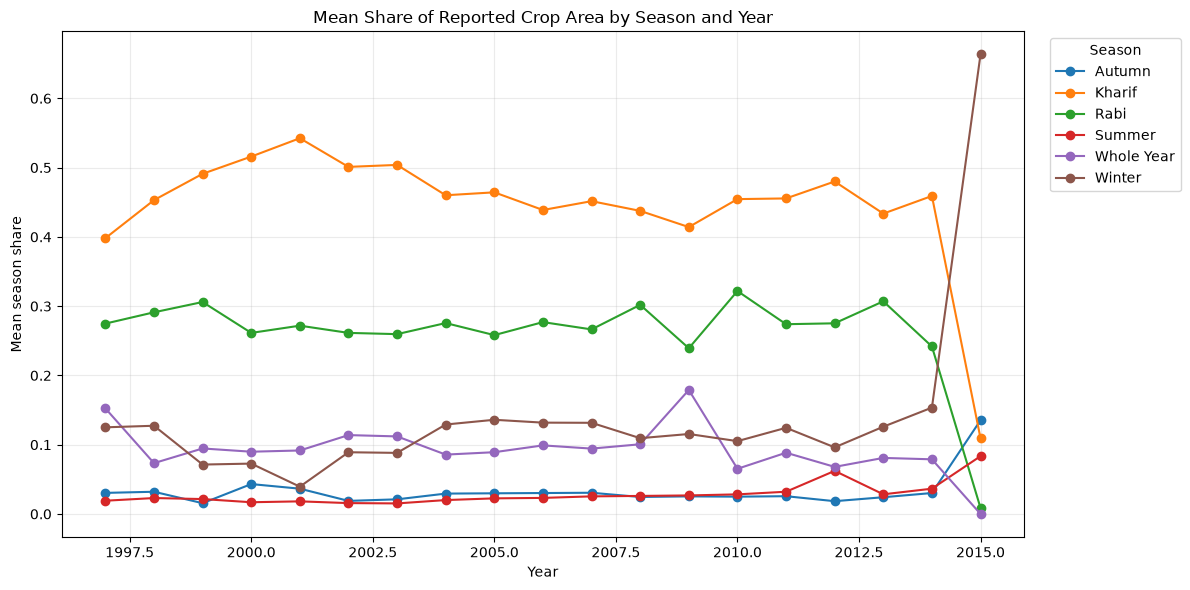

,count,mean,std,min,25%,50%,75%,max
Autumn,"9,839.0000",0.0276,0.0794,0.0000,0.0000,0.0000,0.0000,1.0000
Kharif,"9,839.0000",0.4634,0.3173,0.0000,0.1611,0.4792,0.7305,1.0000
Rabi,"9,839.0000",0.2750,0.2335,0.0000,0.0446,0.2357,0.4767,1.0000
Summer,"9,839.0000",0.0255,0.0678,0.0000,0.0000,0.0000,0.0133,1.0000
Whole Year,"9,839.0000",0.0973,0.1978,0.0000,0.0011,0.0227,0.0854,1.0000
Winter,"9,839.0000",0.1111,0.2332,0.0000,0.0000,0.0000,0.0000,0.9902


In [9]:
season_columns = [column for column in season_matrix.columns if column not in KEYS]
if not season_columns:
    raise ValueError("No season-share columns were found.")

season_means = season_matrix.groupby("Crop_Year")[season_columns].mean()

ax = season_means.plot(marker="o", figsize=(12, 6))
ax.set_title("Mean Share of Reported Crop Area by Season and Year")
ax.set_xlabel("Year")
ax.set_ylabel("Mean season share")
ax.legend(title="Season", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_season_share_trends.png", dpi=160, bbox_inches="tight")
plt.show()

display(season_matrix[season_columns].describe().T)

## 9. Inspect single-crop observations

Notebook 03 flagged district-years with only one recorded crop category. These records have a mathematically concentrated portfolio, but the data alone cannot tell us whether this reflects genuine specialization or incomplete reporting. Inspect them separately before using them to make broad claims.

In [10]:
single_crop = features.loc[
    features["single_crop_observation"].eq(True),
    KEYS + [
        "crop_richness",
        "dominant_crop",
        "top_1_crop_share",
        "total_reported_crop_area_ha",
    ],
].sort_values(["Crop_Year", "State_Name", "District_Name"])

print("Single-crop observations:", len(single_crop))
display(single_crop.head(30))

Single-crop observations: 27


,State_Name,District_Name,Crop_Year,crop_richness,dominant_crop,top_1_crop_share,total_reported_crop_area_ha
2904,Jammu and Kashmir,KARGIL,1997,1,Wheat,1.0000,"1,603.0000"
2945,Jammu and Kashmir,LEH LADAKH,1997,1,Wheat,1.0000,"3,725.0000"
3202,Karnataka,BANGALORE RURAL,1997,1,Rice,1.0000,"15,785.0000"
5026,Maharashtra,MUMBAI,1997,1,Maize,1.0000,3.0000
5375,Manipur,IMPHAL WEST,1997,1,Rice,1.0000,16.0000
7822,Telangana,HYDERABAD,1997,1,Rice,1.0000,200.0000
3646,Karnataka,UDUPI,1999,1,Rice,1.0000,"69,892.0000"
7143,Rajasthan,PRATAPGARH,1999,1,Banana,1.0000,1.0000
7446,Tamil Nadu,KRISHNAGIRI,1999,1,Black pepper,1.0000,1.0000
7824,Telangana,HYDERABAD,1999,1,Rice,1.0000,37.0000


## 10. Data limitations to carry into modelling

Before clustering or comparing districts, keep these limitations visible:

- **Uneven coverage:** the number of available districts varies by year.
- **2015 incompleteness:** the source contains only a small subset of state/district records for 2015; do not treat it as a complete India-wide year.
- **Name-based matching:** matching district names across years does not prove that district boundaries remained unchanged.
- **Reported area interpretation:** summing crop area across seasons measures gross reported crop area, not unique physical land.
- **Single-crop observations:** these may reflect incomplete reporting as well as genuine specialization.
- **Alias handling:** standardized crop labels and duplicate-resolution choices are documented in `crop_label_audit.csv`; preserve this audit trail.
- **Descriptive analysis:** these data do not explain causes, yields, profitability, soil suitability, or what farmers should grow.

## 11. Export a compact EDA summary

The summary records basic ranges and year coverage for later reporting.

In [11]:
eda_summary = pd.DataFrame({
    "metric": [
        "district_year_observations",
        "year_min",
        "year_max",
        "unique_state_labels",
        "unique_district_name_pairs",
        "mean_crop_richness",
        "median_crop_richness",
        "mean_normalized_evenness",
        "mean_hhi_concentration",
        "single_crop_observations",
    ],
    "value": [
        len(features),
        features["Crop_Year"].min(),
        features["Crop_Year"].max(),
        features["State_Name"].nunique(),
        features[["State_Name", "District_Name"]].drop_duplicates().shape[0],
        features["crop_richness"].mean(),
        features["crop_richness"].median(),
        features["normalized_shannon_evenness"].mean(),
        features["hhi_concentration"].mean(),
        int(features["single_crop_observation"].sum()),
    ],
})

summary_path = PROJECT_ROOT / "outputs" / "reports" / "eda_summary.csv"
summary_path.parent.mkdir(parents=True, exist_ok=True)
eda_summary.to_csv(summary_path, index=False)

print("EDA summary saved to:", summary_path)
display(eda_summary)

print("\nFigures saved in:", FIGURES_DIR)

EDA summary saved to: c:\Users\ajadi\OneDrive\Desktop\CSD\Exploration\AgriShift\outputs\reports\eda_summary.csv


,metric,value
0,district_year_observations,"9,839.0000"
1,year_min,"1,997.0000"
2,year_max,"2,015.0000"
3,unique_state_labels,33.0000
4,unique_district_name_pairs,652.0000
5,mean_crop_richness,21.6696
6,median_crop_richness,22.0000
7,mean_normalized_evenness,0.4873
8,mean_hhi_concentration,0.3788
9,single_crop_observations,27.0000



Figures saved in: c:\Users\ajadi\OneDrive\Desktop\CSD\Exploration\AgriShift\outputs\figures
